# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features



## Pregunta 1 — Desarrollo independiente

Esta copia contiene solo la pregunta 1. Se mantienen los objetivos, las diez predictoras, la semilla 42 y la partición 70/15/15. Se conservan las canciones con popularidad cero que cumplen los restantes filtros. Todos los resultados se recalculan al ejecutar el notebook de principio a fin.

## 0. Configuración y carga de Spotify

Se busca el CSV en `data/raw/` desde el directorio del notebook o en
`notebooks/data/raw/` desde la raíz del proyecto. Si no está disponible localmente,
se descarga con `kagglehub`. No se carga el dataset de la pregunta 2.
Las dependencias se instalan con `pip install -r requirements.txt` desde la raíz.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import sklearn
from matplotlib import pyplot as plt
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    r2_score, root_mean_squared_error, mean_absolute_error,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
pd.set_option('display.max_columns', 20)
seed = 42

predictorias = [
    'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'tempo', 'valence',
]
objetivo_y1 = 'popularity'
objetivo_y2 = 'explicit'
columnas_modelado = predictorias + [objetivo_y1, objetivo_y2]

nombre_csv = 'spotify-tracks-dataset-detailed.csv'
candidatos = [
    Path.cwd() / 'data' / 'raw' / nombre_csv,
    Path.cwd() / 'notebooks' / 'data' / 'raw' / nombre_csv,
]
spotify_file = next((p for p in candidatos if p.is_file()), None)
if spotify_file is None:
    import kagglehub
    directorio = Path(kagglehub.dataset_download(
        'saichaitanyareddyai/spotify-tracks-dataset-audio-features'
    ))
    spotify_file = directorio / nombre_csv

df_spotify = pd.read_csv(spotify_file)
assert set(['track_id'] + columnas_modelado).issubset(df_spotify.columns)
assert df_spotify.shape[0] >= 20_000 and len(columnas_modelado) == 12
assert len(set(predictorias)) == 10
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
print('CSV:', spotify_file)
print('Dataset original:', df_spotify.shape)
print('scikit-learn:', sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


CSV: /Users/hectorvines/Desktop/UDP/Ramos/13vo Semestre/IA/T2/Tarea2_IA/notebooks/data/raw/spotify-tracks-dataset-detailed.csv
Dataset original: (114000, 20)
scikit-learn: 1.8.0


## 1.0 Dataset y variables

Se utiliza el dataset de pistas de Spotify citado en la portada. Cada registro
describe una pista y sus características musicales. Se abordan dos tareas de
aprendizaje supervisado: estimar su popularidad y clasificar su contenido explícito.


| # | Columna | Descripción | Tipo ||---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |

### 1.1 Objetivos y diez predictoras iniciales

Se mantiene **Y₁ = `popularity`** como respuesta cuantitativa de regresión y
**Y₂ = `explicit`** como etiqueta binaria (1: explícita; 0: no explícita).
La popularidad mide alcance, mientras que `explicit` identifica una propiedad del
contenido; son objetivos distintos y requieren selecciones de variables separadas.

Las diez predictoras iniciales son `duration_ms`, `danceability`, `energy`,
`loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`,
`tempo` y `valence`. Se usan exactamente las mismas diez en ambas tareas.

Se excluyen identificadores y texto. También se dejan fuera `key`, `mode` y
`time_signature` para mantener la selección inicial de características continuas:
`key` tiene estructura circular, `mode` es otra variable binaria y el compás es
discreto. La elección de `explicit` se justifica por la tarea de contenido, no por
ser la única variable binaria. Las asociaciones acústicas con ambos objetivos
se investigan empíricamente, sin presuponer que sean nulas ni causales.

### 1.2 Limpieza y división 70/15/15

Se conserva la primera aparición de cada `track_id` para evitar que la misma pista
quede repetida entre particiones. Se mantienen los filtros previos sobre ceros
en `tempo`, `danceability` y `duration_ms`; por tanto, el alcance del estudio
queda limitado a canciones con esas tres características distintas de cero.
Un valor cero no demuestra por sí solo un error, y estos filtros constituyen
una decisión de inclusión heredada, no una prueba de invalidez universal.

**Se retira el filtro de popularidad:** las pistas con `popularity = 0` se
conservan si cumplen los demás criterios. Se verifican explícitamente nulos y
valores finitos en las doce columnas de modelado. Los nulos en texto no usado
no requieren eliminar registros ni imputar información para estos modelos.

In [2]:
nulos_modelado = df_spotify[columnas_modelado].isna().sum()
display(nulos_modelado.rename('nulos_modelado').to_frame())
assert nulos_modelado.sum() == 0, 'Hay nulos en columnas utilizadas por los modelos.'

df_sin_duplicados = df_spotify.drop_duplicates(subset='track_id', keep='first').copy()
mask_valid = (
    (df_sin_duplicados['tempo'] != 0)
    & (df_sin_duplicados['danceability'] != 0)
    & (df_sin_duplicados['duration_ms'] != 0)
)
df_clean = df_sin_duplicados.loc[mask_valid].copy()
df_clean['explicit'] = df_clean['explicit'].astype(int)

conteos_limpieza = pd.DataFrame({
    'etapa': ['Original', 'Una fila por track_id', 'Filtros tempo/danceability/duración'],
    'filas': [len(df_spotify), len(df_sin_duplicados), len(df_clean)],
})
conteos_limpieza['eliminadas_en_etapa'] = (
    conteos_limpieza['filas'].shift(1) - conteos_limpieza['filas']
).fillna(0).astype(int)
display(conteos_limpieza)

estadisticas = pd.DataFrame({
    'original': df_spotify['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
    'limpio': df_clean['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
})
display(estadisticas.round(4))
n_ceros_conservados = int(df_clean['popularity'].eq(0).sum())
assert n_ceros_conservados == int(
    (mask_valid & df_sin_duplicados['popularity'].eq(0)).sum()
)
assert n_ceros_conservados > 0
assert len(df_clean) >= 20_000
assert df_clean['track_id'].is_unique
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert set(df_clean['explicit'].unique()) == {0, 1}

display(Markdown(
    f"Se pasa de **{len(df_spotify):,}** a **{len(df_clean):,}** filas. "
    f"Se conservan **{n_ceros_conservados:,}** pistas con popularidad cero. "
    f"La media de popularidad cambia de **{df_spotify['popularity'].mean():.2f}** "
    f"a **{df_clean['popularity'].mean():.2f}** y su desviación muestral de "
    f"**{df_spotify['popularity'].std():.2f}** a **{df_clean['popularity'].std():.2f}**. "
    f"La proporción explícita en la base limpia es **{df_clean['explicit'].mean():.2%}**."
))

,nulos_modelado
duration_ms,0
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
tempo,0
valence,0


,etapa,filas,eliminadas_en_etapa
0,Original,114000,0
1,Una fila por track_id,89741,24259
2,Filtros tempo/danceability/duración,89583,158


,original,limpio
count,114000.0000,89583.0000
mean,33.2385,33.1918
std,22.3051,20.5928
min,0.0000,0.0000
max,100.0000,100.0000


Se pasa de **114,000** a **89,583** filas. Se conservan **9,443** pistas con popularidad cero. La media de popularidad cambia de **33.24** a **33.19** y su desviación muestral de **22.31** a **20.59**. La proporción explícita en la base limpia es **8.60%**.

In [3]:
split_test = 0.15
split_val = 0.15
split_relative_val = split_val / (1 - split_test)

# Mismo procedimiento previo: división aleatoria, sin estratificación.
temp, df_test = train_test_split(df_clean, test_size=split_test, random_state=seed)
df_train, df_val = train_test_split(
    temp, test_size=split_relative_val, random_state=seed
)
particiones = {'train': df_train, 'val': df_val, 'test': df_test}
resumen_particiones = pd.DataFrame([
    {
        'conjunto': nombre,
        'filas': len(datos),
        'proporcion': len(datos) / len(df_clean),
        'media_popularity': datos['popularity'].mean(),
        'desviacion_popularity': datos['popularity'].std(),
        'proporcion_explicit': datos['explicit'].mean(),
    }
    for nombre, datos in particiones.items()
])
display(resumen_particiones.round(6))

ids = {nombre: set(datos['track_id']) for nombre, datos in particiones.items()}
assert sum(map(len, particiones.values())) == len(df_clean)
assert ids['train'].isdisjoint(ids['val'])
assert ids['train'].isdisjoint(ids['test'])
assert ids['val'].isdisjoint(ids['test'])
assert set.union(*ids.values()) == set(df_clean['track_id'])
assert np.allclose(resumen_particiones['proporcion'], [0.70, 0.15, 0.15], atol=2/len(df_clean))
assert all(set(datos['explicit'].unique()) == {0, 1} for datos in particiones.values())
print('Particiones completas, sin pistas compartidas y con ambas clases presentes.')

,conjunto,filas,proporcion,media_popularity,desviacion_popularity,proporcion_explicit
0,train,62707,0.699988,33.210359,20.609690,0.086035
1,val,13438,0.150006,33.267971,20.649987,0.086397
2,test,13438,0.150006,33.029022,20.456887,0.085429


Particiones completas, sin pistas compartidas y con ambas clases presentes.


## 1.A — Regresión lineal para `popularity`

### 1.A.1 Selección de variables con entrenamiento

Se ordenan las diez predictoras por el valor absoluto de su correlación de Pearson
con `popularity` en `df_train`; se conserva el signo para interpretar la dirección.
Ante un empate exacto se ordena alfabéticamente. Los primeros cinco y tres
elementos definen subconjuntos anidados. Pearson describe asociación lineal
individual: no identifica causalidad, relaciones no lineales ni contribuciones
condicionales. La correlación individual máxima no fija un techo para el R²
de una regresión multivariada.

In [4]:
correlacion_y1 = df_train[predictorias].corrwith(df_train[objetivo_y1])
ranking_y1 = (
    pd.DataFrame({
        'variable': correlacion_y1.index,
        'correlacion': correlacion_y1.to_numpy(),
        'abs_correlacion': correlacion_y1.abs().to_numpy(),
    })
    .sort_values(['abs_correlacion', 'variable'], ascending=[False, True], kind='stable')
    .reset_index(drop=True)
)
assert ranking_y1['correlacion'].notna().all()
listFive = ranking_y1['variable'].head(5).tolist()
listThree = ranking_y1['variable'].head(3).tolist()
configs = {'complete': predictorias.copy(), 'reduce': listFive, 'min': listThree}
assert set(listThree) <= set(listFive) <= set(predictorias)
display(ranking_y1.round(6))
display(Markdown(
    '**Cinco variables:** ' + ', '.join(listFive) + '.\n\n'
    '**Tres variables:** ' + ', '.join(listThree) + '.\n\n'
    'La selección es empírica y univariada: prioriza asociaciones individuales con '
    'la popularidad. No implica que las variables descartadas carezcan de aportes '
    'cuando se combinan con otras.'
))

,variable,correlacion,abs_correlacion
0,instrumentalness,-0.129150,0.129150
1,loudness,0.075280,0.075280
2,danceability,0.066621,0.066621
3,speechiness,-0.045205,0.045205
4,acousticness,-0.040929,0.040929
5,duration_ms,-0.023108,0.023108
6,energy,0.017335,0.017335
7,liveness,-0.015712,0.015712
8,tempo,0.010611,0.010611
9,valence,-0.008018,0.008018


**Cinco variables:** instrumentalness, loudness, danceability, speechiness, acousticness.

**Tres variables:** instrumentalness, loudness, danceability.

La selección es empírica y univariada: prioriza asociaciones individuales con la popularidad. No implica que las variables descartadas carezcan de aportes cuando se combinan con otras.

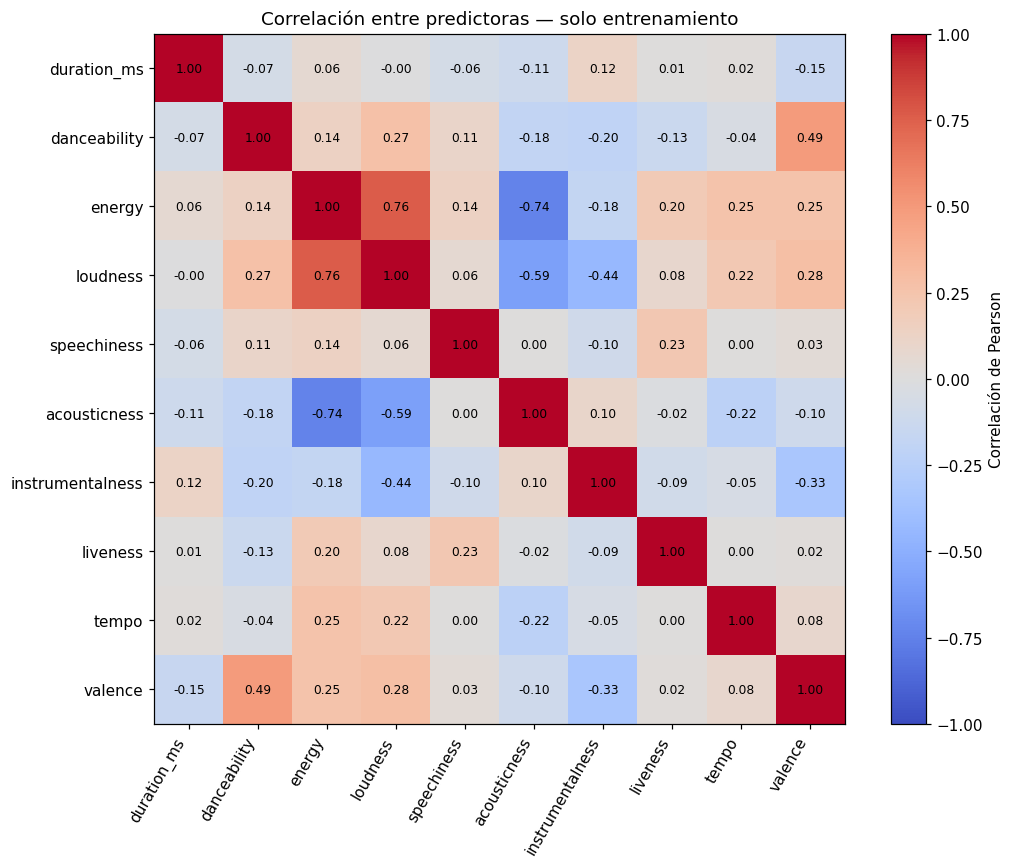

In [5]:
corr_predictoras = df_train[predictorias].corr()
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(corr_predictoras, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(10), predictorias, rotation=60, ha='right')
ax.set_yticks(range(10), predictorias)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{corr_predictoras.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(imagen, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlación entre predictoras — solo entrenamiento')
plt.tight_layout()
plt.show()

### 1.A.2 Entrenamiento de las versiones de 10, 5 y 3 variables

Cada versión ajusta un `StandardScaler` y una `LinearRegression` dentro de un
pipeline usando únicamente entrenamiento. El modelo es

\[
\hat y = \theta_0 + \sum_{j=1}^{p}\theta_j z_j,
\qquad J(\theta)=\frac{1}{2m}\sum_{i=1}^{m}(\hat y^{(i)}-y^{(i)})^2,
\]

donde \(z_j\) es la característica estandarizada. Para estos datos densos,
`LinearRegression` resuelve mínimos cuadrados mediante `lstsq`, sin calcular
explícitamente la inversa de \(X^\top X\). La expresión de la ecuación normal
es una formulación teórica cuando la matriz es invertible; no describe literalmente
la implementación de `.fit()`.

Los coeficientes mostrados corresponden a un aumento de una desviación estándar
de la predictora, manteniendo las demás fijas. La estandarización permite comparar
escalas, pero no elimina multicolinealidad ni otorga interpretación causal.

In [6]:
def evaluar_regresion(y_real, pred):
    return {
        'R2': r2_score(y_real, pred),
        'RMSE': root_mean_squared_error(y_real, pred),
        'MAE': mean_absolute_error(y_real, pred),
    }

y1_train = df_train[objetivo_y1]
y1_val = df_val[objetivo_y1]
models = {}
results = []
parametros_y1 = []

for version, cols in configs.items():
    pipe = make_pipeline(StandardScaler(), LinearRegression())
    pipe.fit(df_train[cols], y1_train)
    models[version] = pipe
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y1_train), ('val', df_val, y1_val)
    ]:
        metricas = evaluar_regresion(objetivo, pipe.predict(datos[cols]))
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
    results.append(fila)
    ajuste = pipe.named_steps['linearregression']
    parametros_y1.append({'version': version, 'variable': 'intercepto', 'coeficiente': ajuste.intercept_})
    parametros_y1.extend(
        {'version': version, 'variable': col, 'coeficiente': coef}
        for col, coef in zip(cols, ajuste.coef_)
    )

table = pd.DataFrame(results)
display(pd.DataFrame(parametros_y1).round(6))

,version,variable,coeficiente
0,complete,intercepto,33.210359
1,complete,duration_ms,-0.446926
2,complete,danceability,1.817208
3,complete,energy,-0.452697
4,complete,loudness,0.470365
5,complete,speechiness,-1.325627
6,complete,acousticness,-0.499330
7,complete,instrumentalness,-2.898726
8,complete,liveness,0.015595
9,complete,tempo,0.237744


### 1.A.3 Comparación en entrenamiento y validación

Se reportan R² (mayor es mejor), RMSE y MAE (menor es mejor, en puntos de
popularidad). R² puede ser negativo si el modelo es peor que la referencia
de la media del conjunto evaluado. Como baseline predictivo se ajusta un
`DummyRegressor` con la media de **entrenamiento**, aplicando esa misma constante
a validación. La referencia no aprende la media de validación.

In [7]:
baseline_y1 = DummyRegressor(strategy='mean').fit(df_train[predictorias], y1_train)
filas_baseline_y1 = []
for conjunto, datos, objetivo in [
    ('train', df_train, y1_train), ('val', df_val, y1_val)
]:
    filas_baseline_y1.append({
        'conjunto': conjunto,
        **evaluar_regresion(objetivo, baseline_y1.predict(datos[predictorias])),
    })
tabla_baseline_y1 = pd.DataFrame(filas_baseline_y1).set_index('conjunto')
table['brecha_R2'] = table['R2_train'] - table['R2_val']
display(table.round(6))
display(tabla_baseline_y1.round(6))

# La identidad usa varianza poblacional del mismo conjunto, no std() con ddof=1.
for conjunto, objetivo in [('train', y1_train), ('val', y1_val)]:
    varianza = objetivo.var(ddof=0)
    assert np.allclose(table[f'R2_{conjunto}'], 1 - table[f'RMSE_{conjunto}']**2 / varianza)
    assert (table[f'RMSE_{conjunto}'] >= table[f'MAE_{conjunto}'] - 1e-10).all()
assert (np.diff(table['R2_train']) <= 1e-10).all()

orden_y1 = table.sort_values(
    ['R2_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
)
mejores_y1 = orden_y1['version'].head(2).tolist()
res_y1 = table.set_index('version')
mejor_y1 = orden_y1.iloc[0]
rmse_baseline_val = tabla_baseline_y1.loc['val', 'RMSE']
mejora_rmse_y1 = 1 - mejor_y1['RMSE_val'] / rmse_baseline_val
caida_10_5 = res_y1.loc['complete', 'R2_val'] - res_y1.loc['reduce', 'R2_val']
caida_5_3 = res_y1.loc['reduce', 'R2_val'] - res_y1.loc['min', 'R2_val']
brechas_y1 = '; '.join(
    f"{fila.version}: {fila.brecha_R2:.5f}" for fila in table.itertuples()
)
display(Markdown(f"""
**Nivel de desempeño.** La mejor versión en validación es **{mejor_y1['version']}**,
con R² = **{mejor_y1['R2_val']:.4f}**, RMSE = **{mejor_y1['RMSE_val']:.3f}** y
MAE = **{mejor_y1['MAE_val']:.3f}**. El baseline de media obtiene RMSE =
**{rmse_baseline_val:.3f}**; la reducción relativa de RMSE es **{mejora_rmse_y1:.2%}**.
Esta referencia permite valorar el aporte del modelo sin confundir estabilidad
entre conjuntos con alta capacidad predictiva.

**Generalización.** Las brechas R² de entrenamiento menos validación son
**{brechas_y1}**. En la versión completa, R² es
**{mejor_y1['R2_train']:.4f}** en entrenamiento y **{mejor_y1['R2_val']:.4f}**
en validación: no aparece una ventaja marcada del entrenamiento. El R² bajo
en ambos y la mejora de RMSE de **{mejora_rmse_y1:.2%}** frente a la media
muestran capacidad predictiva limitada con estas características y este modelo.
La cercanía entre conjuntos no basta para identificar la causa de esa limitación.

**Cantidad de variables.** El cambio de R² en validación al pasar de 10 a 5 es
**{caida_10_5:+.5f}**, y de 5 a 3 es **{caida_5_3:+.5f}** (valor positivo indica
caída). Reducir variables modifica tanto la complejidad como la información
disponible. En esta partición las tres métricas de validación favorecen conservar
las diez variables; la pérdida de R² de 10 a 5 es mayor que la de 5 a 3.
El ranking univariado no garantiza conservar las mejores combinaciones y puede
descartar variables que aportan información condicional. Las diferencias
observadas no establecen una regla general para otras particiones.

**Selección fijada antes de prueba:** mayor R² en validación; ante empate exacto,
menor cantidad de variables y luego nombre de versión. Las versiones elegidas son
**{', '.join(mejores_y1)}**.
"""))

,version,n_vars,R2_train,RMSE_train,MAE_train,R2_val,RMSE_val,MAE_val,brecha_R2
0,complete,10,0.030716,20.290534,16.714511,0.032589,20.309968,16.749437,-0.001872
1,reduce,5,0.022696,20.374310,16.864474,0.022692,20.413585,16.908450,0.000003
2,min,3,0.018605,20.416903,16.977155,0.018456,20.457777,17.024529,0.000149


,R2,RMSE,MAE
conjunto,,,
train,0.000000,20.609526,17.262552
val,-0.000008,20.649299,17.276791



**Nivel de desempeño.** La mejor versión en validación es **complete**,
con R² = **0.0326**, RMSE = **20.310** y
MAE = **16.749**. El baseline de media obtiene RMSE =
**20.649**; la reducción relativa de RMSE es **1.64%**.
Esta referencia permite valorar el aporte del modelo sin confundir estabilidad
entre conjuntos con alta capacidad predictiva.

**Generalización.** Las brechas R² de entrenamiento menos validación son
**complete: -0.00187; reduce: 0.00000; min: 0.00015**. En la versión completa, R² es
**0.0307** en entrenamiento y **0.0326**
en validación: no aparece una ventaja marcada del entrenamiento. El R² bajo
en ambos y la mejora de RMSE de **1.64%** frente a la media
muestran capacidad predictiva limitada con estas características y este modelo.
La cercanía entre conjuntos no basta para identificar la causa de esa limitación.

**Cantidad de variables.** El cambio de R² en validación al pasar de 10 a 5 es
**+0.00990**, y de 5 a 3 es **+0.00424** (valor positivo indica
caída). Reducir variables modifica tanto la complejidad como la información
disponible. En esta partición las tres métricas de validación favorecen conservar
las diez variables; la pérdida de R² de 10 a 5 es mayor que la de 5 a 3.
El ranking univariado no garantiza conservar las mejores combinaciones y puede
descartar variables que aportan información condicional. Las diferencias
observadas no establecen una regla general para otras particiones.

**Selección fijada antes de prueba:** mayor R² en validación; ante empate exacto,
menor cantidad de variables y luego nombre de versión. Las versiones elegidas son
**complete, reduce**.


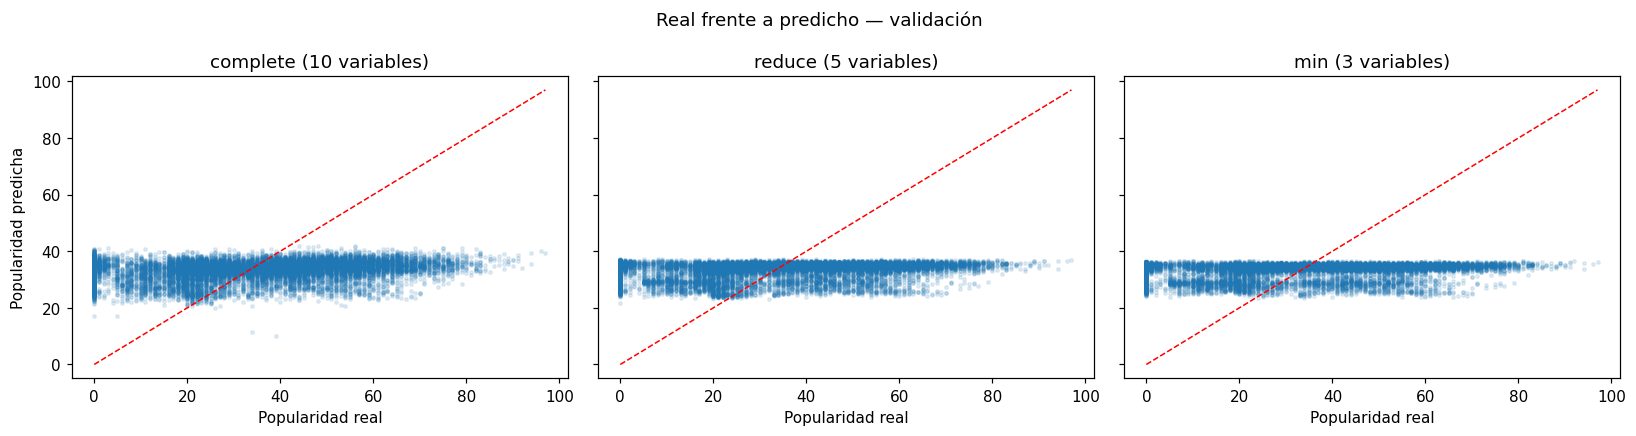

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (version, cols) in zip(ejes, configs.items()):
    pred = models[version].predict(df_val[cols])
    ax.scatter(y1_val, pred, s=5, alpha=0.12)
    limites = [min(y1_val.min(), pred.min()), max(y1_val.max(), pred.max())]
    ax.plot(limites, limites, 'r--', linewidth=1)
    ax.set_title(f'{version} ({len(cols)} variables)')
    ax.set_xlabel('Popularidad real')
ejes[0].set_ylabel('Popularidad predicha')
fig.suptitle('Real frente a predicho — validación')
plt.tight_layout()
plt.show()

### 1.A.4 Prueba de las dos mejores versiones lineales

Las versiones ya se eligieron en validación. Se aplican los pipelines entrenados,
sin ejecutar `.fit()` ni modificar columnas o parámetros después de ver prueba.

In [9]:
y1_test = df_test[objetivo_y1]
tabla_test_y1 = pd.DataFrame([
    {
        'version': version,
        'n_vars': len(configs[version]),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_regresion(
            y1_test, models[version].predict(df_test[configs[version]])
        ).items()},
    }
    for version in mejores_y1
])
comparacion_test_y1 = tabla_test_y1.merge(
    table[['version', 'R2_val', 'RMSE_val', 'MAE_val']], on='version', validate='one_to_one'
)
comparacion_test_y1['cambio_R2_test_val'] = (
    comparacion_test_y1['R2_test'] - comparacion_test_y1['R2_val']
)
display(comparacion_test_y1.round(6))
detalle_prueba_y1 = '; '.join(
    f"{f.version}: R² validación {f.R2_val:.4f}, prueba {f.R2_test:.4f} "
    f"(cambio {f.cambio_R2_test_val:+.4f})"
    for f in comparacion_test_y1.itertuples()
)
display(Markdown(
    '**Contraste con validación.** ' + detalle_prueba_y1 + '. '
    'La diferencia estima la variación entre estas particiones; una sola división '
    'no proporciona intervalos de incertidumbre ni demuestra estabilidad en otras poblaciones. '
    'Los resultados de prueba se reportan sin usarlos para revisar la selección.'
))

,version,n_vars,R2_test,RMSE_test,MAE_test,R2_val,RMSE_val,MAE_val,cambio_R2_test_val
0,complete,10,0.032671,20.119189,16.589625,0.032589,20.309968,16.749437,0.000083
1,reduce,5,0.022793,20.221657,16.763151,0.022692,20.413585,16.908450,0.000100


**Contraste con validación.** complete: R² validación 0.0326, prueba 0.0327 (cambio +0.0001); reduce: R² validación 0.0227, prueba 0.0228 (cambio +0.0001). La diferencia estima la variación entre estas particiones; una sola división no proporciona intervalos de incertidumbre ni demuestra estabilidad en otras poblaciones. Los resultados de prueba se reportan sin usarlos para revisar la selección.

## 1.B — Regresión logística para `explicit`

### 1.B.1 Selección de variables con entrenamiento

Se calcula, para cada predictora, la diferencia absoluta entre su media en la
clase 1 y en la clase 0, dividida por su desviación estándar muestral en todo
entrenamiento. La estandarización evita que las unidades dominen el ranking.
Los empates exactos se resuelven alfabéticamente. Las listas de cinco y tres
variables se obtienen de este ranking nuevo y usan nombres distintos a las de Y₁.

El criterio mide separación de medias y puede omitir relaciones que no cambian
el promedio. Es una selección univariada, no una garantía de la mejor combinación.
Pearson con una etiqueta binaria equivale a la correlación punto-biserial y también
es válido para describir esa asociación; no se descarta por el tipo binario.

In [10]:
y2_train = df_train[objetivo_y2]
y2_val = df_val[objetivo_y2]
medias_y2 = df_train.groupby(objetivo_y2)[predictorias].mean()
desviaciones_y2 = df_train[predictorias].std(ddof=1)
assert (desviaciones_y2 > 0).all(), 'El ranking requiere predictoras no constantes.'
diferencias_y2 = medias_y2.loc[1] - medias_y2.loc[0]
ranking_y2 = pd.DataFrame({
    'variable': predictorias,
    'media_no_explicita': medias_y2.loc[0, predictorias].to_numpy(),
    'media_explicita': medias_y2.loc[1, predictorias].to_numpy(),
    'diferencia_con_signo': diferencias_y2.loc[predictorias].to_numpy(),
    'desviacion_train': desviaciones_y2.loc[predictorias].to_numpy(),
    'puntaje': (diferencias_y2.abs() / desviaciones_y2).loc[predictorias].to_numpy(),
}).sort_values(['puntaje', 'variable'], ascending=[False, True], kind='stable').reset_index(drop=True)

lista_5_y2 = ranking_y2['variable'].head(5).tolist()
lista_3_y2 = ranking_y2['variable'].head(3).tolist()
configs_y2 = {'complete': predictorias.copy(), 'reduce': lista_5_y2, 'min': lista_3_y2}
assert set(lista_3_y2) <= set(lista_5_y2) <= set(predictorias)
assert configs['reduce'] == listFive and configs['min'] == listThree
display(ranking_y2.round(6))

sentido_variables = {
    'duration_ms': 'la duración describe la extensión de la pista, sin indicar por sí sola el lenguaje utilizado',
    'danceability': 'la bailabilidad puede recoger asociaciones con estilos y repertorios',
    'energy': 'la energía caracteriza intensidad acústica y posibles diferencias entre repertorios',
    'loudness': 'el volumen medio recoge diferencias de producción y estilo',
    'speechiness': 'la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal',
    'acousticness': 'el carácter acústico puede distinguir estilos presentes con distinta frecuencia en cada clase',
    'instrumentalness': 'la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito',
    'liveness': 'el carácter en vivo describe el contexto de grabación y puede actuar como asociación indirecta',
    'tempo': 'el tempo caracteriza patrones rítmicos, con una relación posible e indirecta con el repertorio',
    'valence': 'la valencia describe el carácter musical percibido, no el significado literal de la letra',
}
justificacion_y2 = '\n'.join(
    f"- **{variable}:** {sentido_variables[variable]}." for variable in lista_5_y2
)
display(Markdown(
    '**Cinco variables:** ' + ', '.join(lista_5_y2) + '.\n\n'
    '**Tres variables:** ' + ', '.join(lista_3_y2) + '.\n\n'
    '**Pertinencia conceptual de las seleccionadas:**\n\n' + justificacion_y2
    + '\n\nEstas conexiones son explicaciones posibles de asociaciones; el dataset '
    'no contiene letras ni permite establecer causalidad. La justificación empírica '
    'es el puntaje mostrado en la tabla. La coincidencia eventual con el ranking '
    'de Y₁ no invalidaría el procedimiento: lo importante es calcularlo contra Y₂.'
))

,variable,media_no_explicita,media_explicita,diferencia_con_signo,desviacion_train,puntaje
0,speechiness,0.076201,0.208471,0.132269,0.112947,1.171072
1,danceability,0.556055,0.629546,0.073491,0.175328,0.419161
2,instrumentalness,0.184492,0.054454,-0.130038,0.323907,0.401467
3,loudness,-8.665773,-6.601828,2.063945,5.198618,0.397018
4,energy,0.627032,0.720494,0.093462,0.255929,0.365186
5,acousticness,0.336660,0.226005,-0.110655,0.338193,0.327194
6,duration_ms,231238.335392,205405.291566,-25833.043826,108148.011290,0.238867
7,liveness,0.213941,0.241731,0.027790,0.193941,0.143292
8,tempo,122.335968,121.676397,-0.659571,29.720829,0.022192
9,valence,0.469498,0.468583,-0.000915,0.262406,0.003487


**Cinco variables:** speechiness, danceability, instrumentalness, loudness, energy.

**Tres variables:** speechiness, danceability, instrumentalness.

**Pertinencia conceptual de las seleccionadas:**

- **speechiness:** la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal.
- **danceability:** la bailabilidad puede recoger asociaciones con estilos y repertorios.
- **instrumentalness:** la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito.
- **loudness:** el volumen medio recoge diferencias de producción y estilo.
- **energy:** la energía caracteriza intensidad acústica y posibles diferencias entre repertorios.

Estas conexiones son explicaciones posibles de asociaciones; el dataset no contiene letras ni permite establecer causalidad. La justificación empírica es el puntaje mostrado en la tabla. La coincidencia eventual con el ranking de Y₁ no invalidaría el procedimiento: lo importante es calcularlo contra Y₂.

### 1.B.2 Entrenamiento de las versiones de 10, 5 y 3 variables

La regresión logística estima
\(P(Y_2=1\mid z)=1/(1+e^{-(\theta_0+\theta^\top z)})\).
Su ajuste minimiza una pérdida logística con regularización L2. Se mantiene
`C=1`, `solver='lbfgs'`, `max_iter=1000` y `class_weight=None` en las tres versiones.
L-BFGS es un método cuasi-Newton, no el descenso de gradiente elemental.
El escalamiento se aprende dentro de cada pipeline solo con entrenamiento.

Se utiliza el umbral predeterminado de 0,5 para obtener clases mediante `predict`.
ROC-AUC usa las probabilidades de la clase 1, no esas clases discretizadas.
No se buscan hiperparámetros, pesos ni umbrales adicionales en esta etapa.
La métrica decisora será F1 de la clase positiva; los desempates usarán ROC-AUC,
menor número de variables y, finalmente, nombre de versión.

In [11]:
modelos_y2 = {}
for version, cols in configs_y2.items():
    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000, class_weight=None),
    )
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(df_train[cols], y2_train)
    modelos_y2[version] = pipe
    print(version, ':', len(cols), 'variables; iteraciones:',
          pipe.named_steps['logisticregression'].n_iter_.tolist())

complete : 10 variables; iteraciones: [13]
reduce : 5 variables; iteraciones: [11]
min : 3 variables; iteraciones: [10]


### 1.B.3 Comparación en entrenamiento y validación

Se considera positiva la clase `explicit = 1`. Precisión mide el acierto entre
las predicciones positivas; recall mide la fracción de positivos reales detectados;
F1 combina ambas. Si no se predicen positivos, se reporta cero mediante
`zero_division=0`, junto con la matriz que permite reconocer ese comportamiento.

Accuracy se interpreta frente a un clasificador que siempre responde la clase
mayoritaria aprendida en entrenamiento. ROC-AUC describe ordenamiento de las
probabilidades y no garantiza un buen desempeño en el umbral 0,5. Se reportan
las cinco métricas para ambos conjuntos y las matrices de las tres versiones.

In [12]:
def evaluar_clasificacion(y_real, pred, proba_positiva):
    return {
        'accuracy': accuracy_score(y_real, pred),
        'precision': precision_score(y_real, pred, pos_label=1, zero_division=0),
        'recall': recall_score(y_real, pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_real, pred, pos_label=1, zero_division=0),
        'auc': roc_auc_score(y_real, proba_positiva),
    }

def probabilidad_positiva(estimador, X):
    columna_positiva = list(estimador.classes_).index(1)
    return estimador.predict_proba(X)[:, columna_positiva]

filas_clases = []
for conjunto, objetivo in [('train', y2_train), ('val', y2_val)]:
    for clase, conteo in objetivo.value_counts().sort_index().items():
        filas_clases.append({
            'conjunto': conjunto, 'clase': clase,
            'filas': conteo, 'proporcion': conteo / len(objetivo),
        })
tabla_clases_y2 = pd.DataFrame(filas_clases)
display(tabla_clases_y2.round(6))

resultados_y2 = []
matrices_y2 = {}
for version, cols in configs_y2.items():
    pipe = modelos_y2[version]
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y2_train), ('val', df_val, y2_val)
    ]:
        pred = pipe.predict(datos[cols])
        proba = probabilidad_positiva(pipe, datos[cols])
        metricas = evaluar_clasificacion(objetivo, pred, proba)
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
        matrices_y2[(version, conjunto)] = confusion_matrix(objetivo, pred, labels=[0, 1])
    fila['brecha_f1'] = fila['f1_train'] - fila['f1_val']
    fila['brecha_auc'] = fila['auc_train'] - fila['auc_val']
    resultados_y2.append(fila)

tabla_y2 = pd.DataFrame(resultados_y2)
display(tabla_y2.round(6))
baseline_y2 = DummyClassifier(strategy='most_frequent').fit(df_train[predictorias], y2_train)
tabla_baseline_y2 = pd.DataFrame([
    {
        'conjunto': conjunto,
        **evaluar_clasificacion(
            objetivo, baseline_y2.predict(datos[predictorias]),
            probabilidad_positiva(baseline_y2, datos[predictorias]),
        ),
    }
    for conjunto, datos, objetivo in [('train', df_train, y2_train), ('val', df_val, y2_val)]
]).set_index('conjunto')
display(tabla_baseline_y2.round(6))

orden_y2 = tabla_y2.sort_values(
    ['f1_val', 'auc_val', 'n_vars', 'version'],
    ascending=[False, False, True, True], kind='stable',
)
mejores_y2 = orden_y2['version'].head(2).tolist()
mejor_y2 = orden_y2.iloc[0]
mejor_version_y2 = mejor_y2['version']
vn, fp, fn, vp = matrices_y2[(mejor_version_y2, 'val')].ravel()
res_y2 = tabla_y2.set_index('version')
caida_f1_10_5 = res_y2.loc['complete', 'f1_val'] - res_y2.loc['reduce', 'f1_val']
caida_f1_5_3 = res_y2.loc['reduce', 'f1_val'] - res_y2.loc['min', 'f1_val']
version_mayor_accuracy = tabla_y2.sort_values(
    ['accuracy_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
).iloc[0]
display(Markdown(f"""
**Desbalance y referencia.** La proporción positiva en validación es
**{y2_val.mean():.2%}**. El baseline mayoritario obtiene accuracy
**{tabla_baseline_y2.loc['val', 'accuracy']:.2%}**, F1
**{tabla_baseline_y2.loc['val', 'f1']:.4f}** y recall
**{tabla_baseline_y2.loc['val', 'recall']:.4f}**. Por ello, accuracy debe leerse
junto a la capacidad de detectar contenido explícito.

**Mejor versión según el criterio fijado.** **{mejor_version_y2}** obtiene en
validación precisión **{mejor_y2['precision_val']:.4f}**, recall
**{mejor_y2['recall_val']:.4f}**, F1 **{mejor_y2['f1_val']:.4f}** y ROC-AUC
**{mejor_y2['auc_val']:.4f}**. Su matriz contiene **{vn:,} VN**, **{fp:,} FP**,
**{fn:,} FN** y **{vp:,} VP**. F1 se prioriza porque interesa recuperar la clase
explícita sin ignorar la precisión de esas detecciones, manteniendo el umbral 0,5.
La proporción de positivos reales no detectados es **{fn / (fn + vp):.2%}**:
la recuperación sigue siendo limitada pese a superar al baseline.

La mayor accuracy de validación corresponde a **{version_mayor_accuracy['version']}**
(**{version_mayor_accuracy['accuracy_val']:.2%}**), cuyo F1 es
**{version_mayor_accuracy['f1_val']:.4f}**. Esa diferencia de orden muestra por qué
la métrica de selección debe reflejar la detección de la clase positiva y no
solo el acierto global dominado por las canciones no explícitas.

**Generalización y reducción.** Para esa versión, la brecha F1 de entrenamiento
menos validación es **{mejor_y2['brecha_f1']:+.5f}**, y la brecha ROC-AUC es
**{mejor_y2['brecha_auc']:+.5f}**. Las caídas de F1 en validación al pasar de
10 a 5 y de 5 a 3 variables son **{caida_f1_10_5:+.5f}** y
**{caida_f1_5_3:+.5f}**, respectivamente. Los efectos sobre F1 y AUC pueden diferir:
una mide decisiones a un umbral fijo y la otra el ordenamiento de probabilidades.

Las dos versiones seleccionadas antes de consultar prueba son
**{', '.join(mejores_y2)}**. No se modifica el umbral para mejorar estos resultados.
"""))

,conjunto,clase,filas,proporcion
0,train,0,57312,0.913965
1,train,1,5395,0.086035
2,val,0,12277,0.913603
3,val,1,1161,0.086397


,version,n_vars,accuracy_train,precision_train,recall_train,f1_train,auc_train,accuracy_val,precision_val,recall_val,f1_val,auc_val,brecha_f1,brecha_auc
0,complete,10,0.915241,0.537037,0.107507,0.179151,0.817292,0.914124,0.513619,0.113695,0.186178,0.829415,-0.007027,-0.012123
1,reduce,5,0.915767,0.570361,0.084893,0.147790,0.783246,0.915240,0.559140,0.089578,0.154417,0.789141,-0.006628,-0.005895
2,min,3,0.915863,0.578393,0.081372,0.142671,0.767826,0.915389,0.568182,0.086133,0.149589,0.778885,-0.006917,-0.011059


,accuracy,precision,recall,f1,auc
conjunto,,,,,
train,0.913965,0.0,0.0,0.0,0.5
val,0.913603,0.0,0.0,0.0,0.5



**Desbalance y referencia.** La proporción positiva en validación es
**8.64%**. El baseline mayoritario obtiene accuracy
**91.36%**, F1
**0.0000** y recall
**0.0000**. Por ello, accuracy debe leerse
junto a la capacidad de detectar contenido explícito.

**Mejor versión según el criterio fijado.** **complete** obtiene en
validación precisión **0.5136**, recall
**0.1137**, F1 **0.1862** y ROC-AUC
**0.8294**. Su matriz contiene **12,152 VN**, **125 FP**,
**1,029 FN** y **132 VP**. F1 se prioriza porque interesa recuperar la clase
explícita sin ignorar la precisión de esas detecciones, manteniendo el umbral 0,5.
La proporción de positivos reales no detectados es **88.63%**:
la recuperación sigue siendo limitada pese a superar al baseline.

La mayor accuracy de validación corresponde a **min**
(**91.54%**), cuyo F1 es
**0.1496**. Esa diferencia de orden muestra por qué
la métrica de selección debe reflejar la detección de la clase positiva y no
solo el acierto global dominado por las canciones no explícitas.

**Generalización y reducción.** Para esa versión, la brecha F1 de entrenamiento
menos validación es **-0.00703**, y la brecha ROC-AUC es
**-0.01212**. Las caídas de F1 en validación al pasar de
10 a 5 y de 5 a 3 variables son **+0.03176** y
**+0.00483**, respectivamente. Los efectos sobre F1 y AUC pueden diferir:
una mide decisiones a un umbral fijo y la otra el ordenamiento de probabilidades.

Las dos versiones seleccionadas antes de consultar prueba son
**complete, reduce**. No se modifica el umbral para mejorar estos resultados.


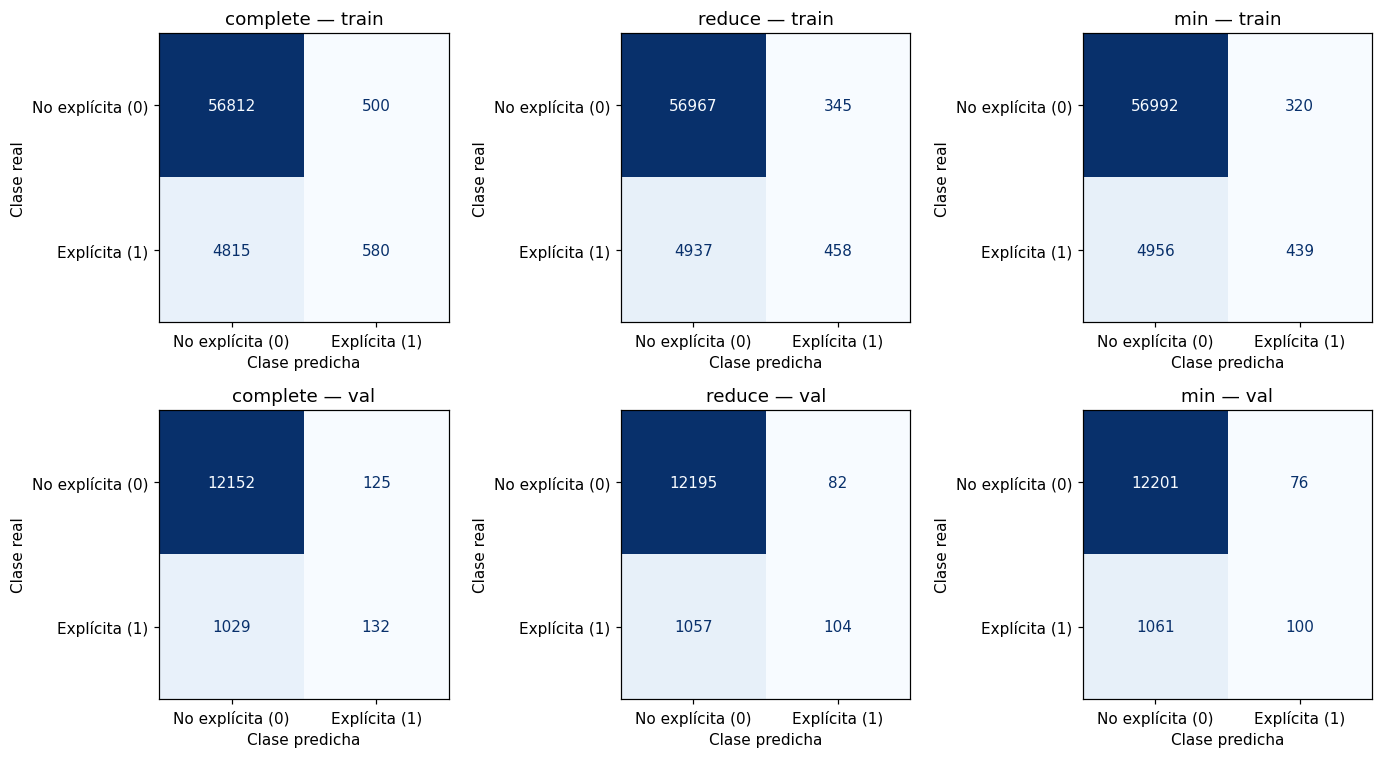

In [13]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
for fila, conjunto in enumerate(['train', 'val']):
    for columna, version in enumerate(configs_y2):
        ConfusionMatrixDisplay(
            confusion_matrix=matrices_y2[(version, conjunto)],
            display_labels=['No explícita (0)', 'Explícita (1)'],
        ).plot(ax=ejes[fila, columna], colorbar=False, cmap='Blues', values_format='d')
        ejes[fila, columna].set_title(f'{version} — {conjunto}')
        ejes[fila, columna].set_xlabel('Clase predicha')
        ejes[fila, columna].set_ylabel('Clase real')
plt.tight_layout()
plt.show()

### 1.B.4 Prueba de las dos mejores versiones logísticas

Se aplican exclusivamente las dos versiones seleccionadas por F1 de validación,
con los desempates ya declarados. Los modelos, columnas y umbral permanecen
fijados. Se reportan métricas y matrices de confusión sin volver a entrenar.

,version,n_vars,accuracy_test,precision_test,recall_test,f1_test,auc_test,f1_val,auc_val,cambio_f1_test_val,cambio_auc_test_val
0,complete,10,0.916059,0.544248,0.107143,0.179039,0.808654,0.186178,0.829415,-0.007138,-0.020761
1,reduce,5,0.915910,0.554217,0.080139,0.140030,0.771338,0.154417,0.789141,-0.014387,-0.017803


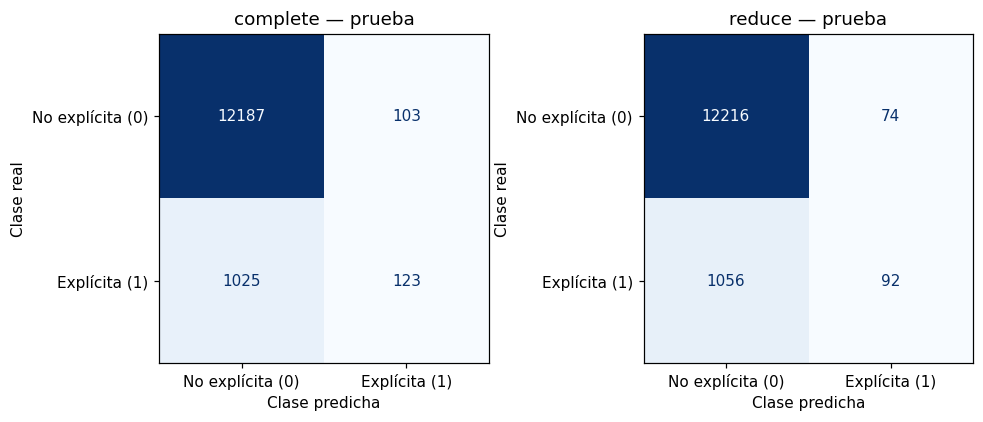

**Contraste con validación.** complete: F1 validación 0.1862, prueba 0.1790 (cambio -0.0071), AUC prueba 0.8087; reduce: F1 validación 0.1544, prueba 0.1400 (cambio -0.0144), AUC prueba 0.7713. Estos resultados describen el desempeño con pistas reservadas bajo la misma partición aleatoria; no acreditan por sí solos generalización a otros artistas o períodos. La selección permanece basada en validación.

In [14]:
y2_test = df_test[objetivo_y2]
filas_test_y2 = []
matrices_test_y2 = {}
for version in mejores_y2:
    pipe = modelos_y2[version]
    cols = configs_y2[version]
    pred = pipe.predict(df_test[cols])
    proba = probabilidad_positiva(pipe, df_test[cols])
    filas_test_y2.append({
        'version': version, 'n_vars': len(cols),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_clasificacion(
            y2_test, pred, proba
        ).items()},
    })
    matrices_test_y2[version] = confusion_matrix(y2_test, pred, labels=[0, 1])

tabla_test_y2 = pd.DataFrame(filas_test_y2)
comparacion_test_y2 = tabla_test_y2.merge(
    tabla_y2[['version', 'f1_val', 'auc_val']], on='version', validate='one_to_one'
)
comparacion_test_y2['cambio_f1_test_val'] = comparacion_test_y2['f1_test'] - comparacion_test_y2['f1_val']
comparacion_test_y2['cambio_auc_test_val'] = comparacion_test_y2['auc_test'] - comparacion_test_y2['auc_val']
display(comparacion_test_y2.round(6))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for ax, version in zip(ejes, mejores_y2):
    ConfusionMatrixDisplay(
        matrices_test_y2[version], display_labels=['No explícita (0)', 'Explícita (1)']
    ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(f'{version} — prueba')
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
plt.tight_layout()
plt.show()

detalle_prueba_y2 = '; '.join(
    f"{f.version}: F1 validación {f.f1_val:.4f}, prueba {f.f1_test:.4f} "
    f"(cambio {f.cambio_f1_test_val:+.4f}), AUC prueba {f.auc_test:.4f}"
    for f in comparacion_test_y2.itertuples()
)
display(Markdown(
    '**Contraste con validación.** ' + detalle_prueba_y2 + '. '
    'Estos resultados describen el desempeño con pistas reservadas bajo la misma '
    'partición aleatoria; no acreditan por sí solos generalización a otros artistas '
    'o períodos. La selección permanece basada en validación.'
))

## 1.C — Análisis final

Se integran los resultados de ambas tareas. Las diferencias entre versiones se
interpretan dentro de cada problema: R² y F1 miden objetivos distintos y sus
valores no permiten comparar directamente cuál tarea es más difícil.

In [15]:
pares_correlacion = [
    (a, b, corr_predictoras.loc[a, b])
    for i, a in enumerate(predictorias) for b in predictorias[i + 1:]
]
par_mayor = max(pares_correlacion, key=lambda par: abs(par[2]))
prueba_mejor_y1 = tabla_test_y1.set_index('version').loc[mejor_y1['version']]
prueba_mejor_y2 = tabla_test_y2.set_index('version').loc[mejor_y2['version']]
brechas_f1_y2 = '; '.join(
    f"{f.version}: {f.brecha_f1:+.5f}" for f in tabla_y2.itertuples()
)
comparacion_reduccion = pd.DataFrame({
    'version': list(configs),
    'n_vars': [len(cols) for cols in configs.values()],
    'R2_train': table['R2_train'].to_numpy(),
    'R2_val': table['R2_val'].to_numpy(),
    'brecha_R2': table['brecha_R2'].to_numpy(),
    'F1_train': tabla_y2['f1_train'].to_numpy(),
    'F1_val': tabla_y2['f1_val'].to_numpy(),
    'brecha_F1': tabla_y2['brecha_f1'].to_numpy(),
    'AUC_val': tabla_y2['auc_val'].to_numpy(),
})
display(comparacion_reduccion.round(6))

display(Markdown(f"""
### Desempeño y generalización

La mejor regresión explica **{mejor_y1['R2_val']:.2%}** de la variabilidad de la
popularidad en validación y reduce el RMSE del baseline en **{mejora_rmse_y1:.2%}**.
Las brechas de R² son **{brechas_y1}**. El aporte frente a la referencia debe
valorarse junto con el error que permanece, no solo con la posición en el ranking.

En clasificación, la mejor versión alcanza F1 **{mejor_y2['f1_val']:.4f}** y recall
**{mejor_y2['recall_val']:.4f}** en validación, frente a una proporción positiva de
**{y2_val.mean():.2%}**. Las brechas de F1 son **{brechas_f1_y2}**.
Un AUC de **{mejor_y2['auc_val']:.4f}** puede coexistir con una recuperación limitada
de positivos al umbral 0,5: ordenar probabilidades y tomar decisiones son aspectos
distintos. Accuracy debe contrastarse con el baseline mayoritario.

En prueba, las versiones elegidas como primeras en validación alcanzan R²
**{prueba_mejor_y1['R2_test']:.4f}** y RMSE **{prueba_mejor_y1['RMSE_test']:.3f}**
en regresión, y F1 **{prueba_mejor_y2['f1_test']:.4f}**, recall
**{prueba_mejor_y2['recall_test']:.4f}** y AUC **{prueba_mejor_y2['auc_test']:.4f}**
en clasificación. Se mantiene el diagnóstico de mejora modesta sobre la media
en regresión y baja detección de positivos al umbral fijo en clasificación.

### Influencia de reducir variables

En regresión, las caídas de R² de validación son **{caida_10_5:+.5f}** para 10→5
y **{caida_5_3:+.5f}** para 5→3. En clasificación, las caídas de F1 son
**{caida_f1_10_5:+.5f}** y **{caida_f1_5_3:+.5f}**. Un cambio negativo significa que
la versión reducida mejora esa métrica. El número de variables por sí solo no
determina la generalización: importan la información eliminada y el criterio de
selección. Los subconjuntos reducidos difieren entre tareas porque se rankean
contra objetivos distintos. Estas comparaciones corresponden a las versiones
evaluadas y no prueban que sean las mejores de todos los subconjuntos posibles.

### Overfitting y underfitting

En esta partición no se observa el patrón clásico de overfitting: las versiones
completas obtienen R² **{mejor_y1['R2_train']:.4f}** y F1
**{mejor_y2['f1_train']:.4f}** en entrenamiento, ligeramente inferiores a sus
resultados en validación. En las versiones reducidas tampoco aparece una brecha
grande a favor de entrenamiento. Los resultados de prueba mantienen la baja
capacidad explicativa de popularidad y la baja recuperación de explícitos.
Esto no demuestra ausencia de sobreajuste en otras particiones o poblaciones.

Un desempeño limitado en ambos conjuntos es compatible con underfitting, pero
también con ruido o información predictiva ausente. Los experimentos realizados
no permiten distinguir definitivamente esas causas. La correlación individual
más alta con Y₁ es **{ranking_y1.iloc[0]['correlacion']:+.4f}** para
**{ranking_y1.iloc[0]['variable']}**; su cuadrado no es un techo del R² multivariado.
No se puede concluir, a partir de este ranking, que un modelo más flexible sería
incapaz de mejorar.

### Alcance y limitaciones

La popularidad puede depender de difusión, playlists, trayectoria del artista y
contexto temporal, factores no incluidos entre las diez predictoras. Para contenido
explícito faltan las letras y su análisis lingüístico. Son explicaciones posibles
de las limitaciones predictivas; no se ha medido el efecto causal de esos factores.

La mayor correlación absoluta entre predictoras se observa entre **{par_mayor[0]}**
y **{par_mayor[1]}** (**{par_mayor[2]:+.4f}**). Esta asociación aconseja cautela al
interpretar coeficientes individuales y al usar rankings univariados; no implica
por sí sola que las predicciones sean inválidas. La regularización de la logística
y el umbral fijo también forman parte de la configuración evaluada.

Se conservaron **{n_ceros_conservados:,}** pistas de popularidad cero, evitando
excluir esa parte del objetivo. Aun así, siguen vigentes los filtros sobre tempo,
bailabilidad y duración. La deduplicación impide repetir `track_id`, pero no
garantiza independencia por artista, versiones de una obra ni álbum. La división
aleatoria con una semilla no mide variación entre particiones ni transferencia
temporal. Los resultados de prueba se reportan para las selecciones ya fijadas,
sin utilizarlos para rediseñar los modelos.
"""))

,version,n_vars,R2_train,R2_val,brecha_R2,F1_train,F1_val,brecha_F1,AUC_val
0,complete,10,0.030716,0.032589,-0.001872,0.179151,0.186178,-0.007027,0.829415
1,reduce,5,0.022696,0.022692,0.000003,0.147790,0.154417,-0.006628,0.789141
2,min,3,0.018605,0.018456,0.000149,0.142671,0.149589,-0.006917,0.778885



### Desempeño y generalización

La mejor regresión explica **3.26%** de la variabilidad de la
popularidad en validación y reduce el RMSE del baseline en **1.64%**.
Las brechas de R² son **complete: -0.00187; reduce: 0.00000; min: 0.00015**. El aporte frente a la referencia debe
valorarse junto con el error que permanece, no solo con la posición en el ranking.

En clasificación, la mejor versión alcanza F1 **0.1862** y recall
**0.1137** en validación, frente a una proporción positiva de
**8.64%**. Las brechas de F1 son **complete: -0.00703; reduce: -0.00663; min: -0.00692**.
Un AUC de **0.8294** puede coexistir con una recuperación limitada
de positivos al umbral 0,5: ordenar probabilidades y tomar decisiones son aspectos
distintos. Accuracy debe contrastarse con el baseline mayoritario.

En prueba, las versiones elegidas como primeras en validación alcanzan R²
**0.0327** y RMSE **20.119**
en regresión, y F1 **0.1790**, recall
**0.1071** y AUC **0.8087**
en clasificación. Se mantiene el diagnóstico de mejora modesta sobre la media
en regresión y baja detección de positivos al umbral fijo en clasificación.

### Influencia de reducir variables

En regresión, las caídas de R² de validación son **+0.00990** para 10→5
y **+0.00424** para 5→3. En clasificación, las caídas de F1 son
**+0.03176** y **+0.00483**. Un cambio negativo significa que
la versión reducida mejora esa métrica. El número de variables por sí solo no
determina la generalización: importan la información eliminada y el criterio de
selección. Los subconjuntos reducidos difieren entre tareas porque se rankean
contra objetivos distintos. Estas comparaciones corresponden a las versiones
evaluadas y no prueban que sean las mejores de todos los subconjuntos posibles.

### Overfitting y underfitting

En esta partición no se observa el patrón clásico de overfitting: las versiones
completas obtienen R² **0.0307** y F1
**0.1792** en entrenamiento, ligeramente inferiores a sus
resultados en validación. En las versiones reducidas tampoco aparece una brecha
grande a favor de entrenamiento. Los resultados de prueba mantienen la baja
capacidad explicativa de popularidad y la baja recuperación de explícitos.
Esto no demuestra ausencia de sobreajuste en otras particiones o poblaciones.

Un desempeño limitado en ambos conjuntos es compatible con underfitting, pero
también con ruido o información predictiva ausente. Los experimentos realizados
no permiten distinguir definitivamente esas causas. La correlación individual
más alta con Y₁ es **-0.1292** para
**instrumentalness**; su cuadrado no es un techo del R² multivariado.
No se puede concluir, a partir de este ranking, que un modelo más flexible sería
incapaz de mejorar.

### Alcance y limitaciones

La popularidad puede depender de difusión, playlists, trayectoria del artista y
contexto temporal, factores no incluidos entre las diez predictoras. Para contenido
explícito faltan las letras y su análisis lingüístico. Son explicaciones posibles
de las limitaciones predictivas; no se ha medido el efecto causal de esos factores.

La mayor correlación absoluta entre predictoras se observa entre **energy**
y **loudness** (**+0.7594**). Esta asociación aconseja cautela al
interpretar coeficientes individuales y al usar rankings univariados; no implica
por sí sola que las predicciones sean inválidas. La regularización de la logística
y el umbral fijo también forman parte de la configuración evaluada.

Se conservaron **9,443** pistas de popularidad cero, evitando
excluir esa parte del objetivo. Aun así, siguen vigentes los filtros sobre tempo,
bailabilidad y duración. La deduplicación impide repetir `track_id`, pero no
garantiza independencia por artista, versiones de una obra ni álbum. La división
aleatoria con una semilla no mide variación entre particiones ni transferencia
temporal. Los resultados de prueba se reportan para las selecciones ya fijadas,
sin utilizarlos para rediseñar los modelos.


## Verificación de cierre

Se comprueban integridad de particiones, anidamiento de variables, ajuste de los
escaladores con entrenamiento y evaluación en prueba de exactamente dos versiones
por tarea. Las comprobaciones no vuelven a entrenar modelos ni generan nuevas
evaluaciones de prueba.

In [16]:
assert sum(len(datos) for datos in particiones.values()) == len(df_clean)
assert all(ids[a].isdisjoint(ids[b]) for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')])
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
assert set(configs['complete']) == set(configs_y2['complete']) == set(predictorias)

for configuraciones, modelos in [(configs, models), (configs_y2, modelos_y2)]:
    assert [len(configuraciones[v]) for v in ['complete', 'reduce', 'min']] == [10, 5, 3]
    assert set(configuraciones['min']) <= set(configuraciones['reduce']) <= set(configuraciones['complete'])
    for version, cols in configuraciones.items():
        escalador = modelos[version].named_steps['standardscaler']
        assert escalador.n_samples_seen_ == len(df_train)
        assert list(escalador.feature_names_in_) == cols
        assert np.allclose(escalador.mean_, df_train[cols].mean().to_numpy())
        assert np.allclose(escalador.var_, df_train[cols].var(ddof=0).to_numpy())

assert len(tabla_test_y1) == 2 and tabla_test_y1['version'].tolist() == mejores_y1
assert len(tabla_test_y2) == 2 and tabla_test_y2['version'].tolist() == mejores_y2
assert set(mejores_y1) == set(orden_y1['version'].head(2))
assert set(mejores_y2) == set(orden_y2['version'].head(2))
assert np.isclose(baseline_y1.constant_.item(), y1_train.mean())
for (version, conjunto), matriz in matrices_y2.items():
    assert matriz.sum() == len(particiones[conjunto])
for matriz in matrices_test_y2.values():
    assert matriz.sum() == len(df_test)
assert all(np.isfinite(t.select_dtypes(include='number').to_numpy()).all() for t in [table, tabla_y2, tabla_test_y1, tabla_test_y2])
assert n_ceros_conservados > 0 and seed == 42
print('Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.')

Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.


## Declaración de uso de herramientas generativas

Se utilizó OpenAI Codex para revisar el notebook y la guía, implementar esta copia
de la pregunta 1, retirar el filtro de popularidad cero, recalcular rankings y
modelos, añadir verificaciones de reproducibilidad y redactar los textos de
comparación y análisis de resultados a partir de las métricas calculadas.
Esta declaración registra el alcance efectivo de la asistencia recibida.